# 19/9/25: Body-ordered approximations of atomic properties

* [paper](https://link.springer.com/article/10.1007/s00205-022-01809-w)
* [slides](https://jack.thomaslabs.co.uk/GroupMeetings/slides.pdf)
* [slides - quadrature](https://jack.thomaslabs.co.uk/GroupMeetings/slides.pdf)
* [notes](https://jack.thomaslabs.co.uk/GroupMeetings/notes.pdf)


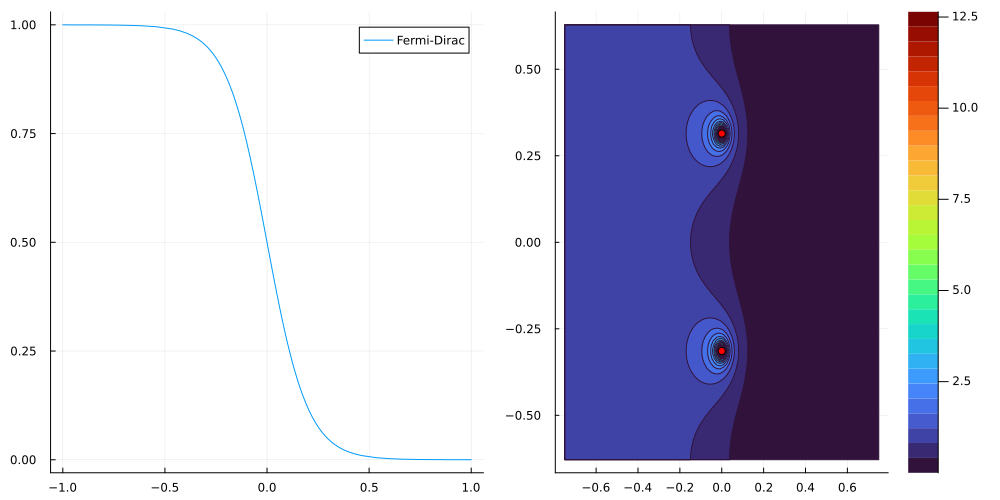

In [ ]:
# | include: false
function f( x; μ = 0, β = 10 )
    return 1/( 1 + exp( β * (x - μ) ) );
end

function F( x, y; μ = 0, β = 10 )
    return 1/( 1 + exp( β * (x+1im*y - μ) ) );
end

using Plots
using LaTeXStrings
using Polynomials

μ = 0.
β = 10. 
i = 1im;

plt1 = plot( f, -1, 1, label="Fermi-Dirac" )

x = range(-.75, .75, length=100)
y = range(-2π/β, 2π/β, length=100)
z = @. abs( F( x', y ) )
plt2 = contourf( x,y,z, 
    levels=30, color=:turbo)
scatter!(plt2, [μ -μ] , [-π/β π/β] , 
    color="red", primary=false)

plot( plt1, plt2, size=(1000,500))

## Equispaced nodes

[ Info: Saved animation to C:\Users\jack6\julia_\images\equispaced.gif


Plots.AnimatedGif("C:\\Users\\jack6\\julia_\\images\\equispaced.gif")
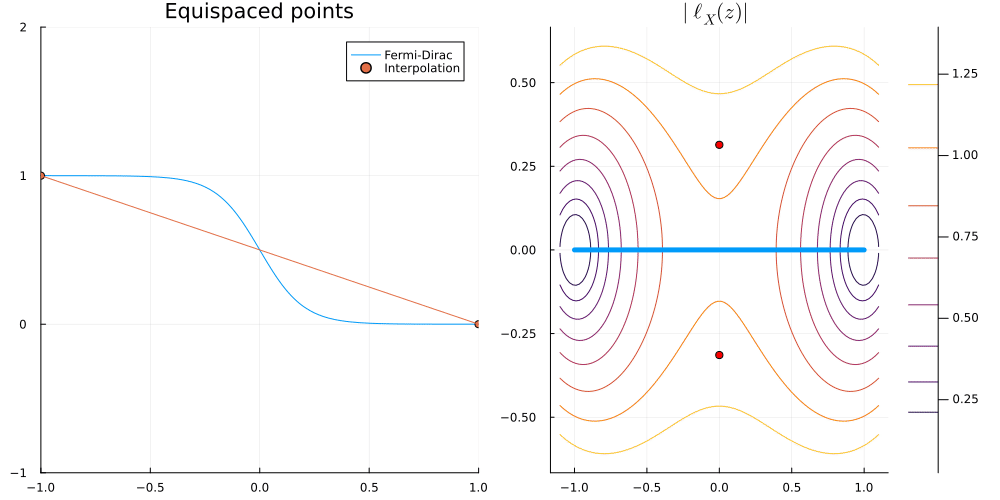

In [ ]:
# | include: false

N = 30;

anim = @animate for n ∈ 2:N
    equispacedNodes = @. -1 + 2*(0:(n-1))/(n-1)
    p1 = fit( equispacedNodes, f.( equispacedNodes ) )

    plt1 = plot( f, 
        label="Fermi-Dirac", title="Equispaced points",
        size=(500,500) )
    scatter!( plt1, equispacedNodes, f.( equispacedNodes ),
        label="Interpolation" )
    plot!( plt1, p1, 
        xlims=[-1,1], ylims=[-1,2], 
        primary=false )
    
    nodePoly = fromroots(Polynomial, equispacedNodes)

    x = range(-1.1, 1.1, length=100)
    y = range(-2π/β, 2π/β, length=100)
    z = @. abs( nodePoly( x' + 1im*y ) ) # imag( p1( x' + 1im*y ) )
    plt2 = contour( x,y,z, 
                levels = ((1.25:.25:3)/exp(1)).^n)
                #color=["red", "blue", "red"],
                #clims=(-10,10) )
    scatter!(plt2, [μ -μ] , [-π/β π/β] , 
        color="red", primary=false, title=L"|\ell_X(z)|")
    plot!(plt2, [-1,1], [0,0], lw=5, primary=false)
    
    plot( plt1, plt2, size=(1000,500) )

end

gif(anim, "images/equispaced.gif", fps = 1)


## Chebyshev nodes

[ Info: Saved animation to C:\Users\jack6\julia_\images\chebyshev.gif


Plots.AnimatedGif("C:\\Users\\jack6\\julia_\\images\\chebyshev.gif")
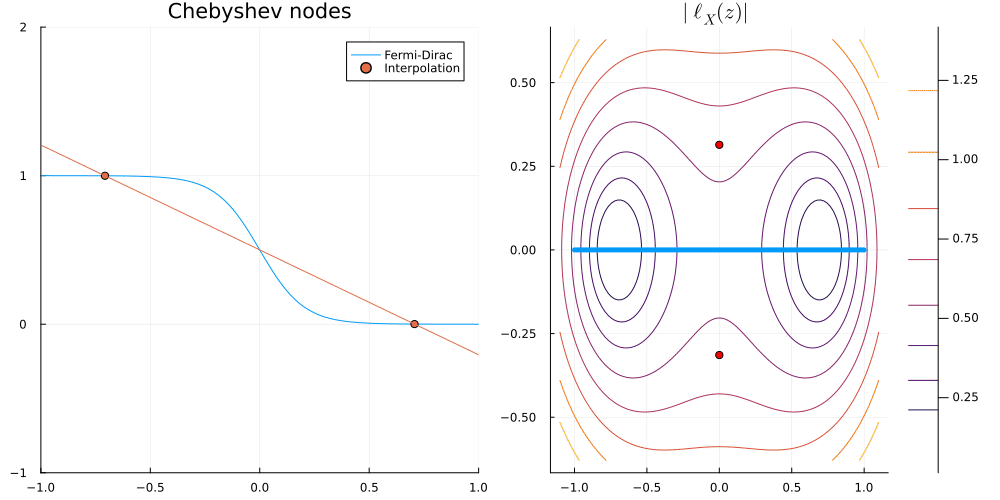

In [ ]:
# | include: false

N = 30;

m = -1:1e-4:1;
err = zeros(N);

anim = @animate for n ∈ 2:N
    chebyshevNodes = @. cos( ( (0:n-1) + 1/2 )*π/n )
    p1 = fit( chebyshevNodes, f.( chebyshevNodes ) )

    err[n] = maximum( abs.( p1.(m) - f.(m) ) )

    plt1 = plot( f, 
        label="Fermi-Dirac", title="Chebyshev nodes",
        size=(500,500) )
    scatter!( plt1, chebyshevNodes, f.( chebyshevNodes ),
        label="Interpolation" )
    plot!( plt1, p1, 
        xlims=[-1,1], ylims=[-1,2], 
        primary=false )
    
    nodePoly = fromroots(Polynomial, chebyshevNodes)

    x = range(-1.1, 1.1, length=100)
    y = range(-2π/β, 2π/β, length=100)
    z = @. abs( nodePoly( x' + 1im*y ) ) # imag( p1( x' + 1im*y ) )
    plt2 = contour( x,y,z, 
                levels = ((1.25:.25:3)/exp(1)).^n)
                #color=["red", "blue", "red"],
                #clims=(-10,10) )
    scatter!(plt2, [μ -μ] , [-π/β π/β] , 
        color="red", primary=false, title=L"|\ell_X(z)|")
    plot!(plt2, [-1,1], [0,0], lw=5, primary=false)

    plot( plt1, plt2, size=(1000,500) )

end

gif(anim, "images/chebyshev.gif", fps = 1)


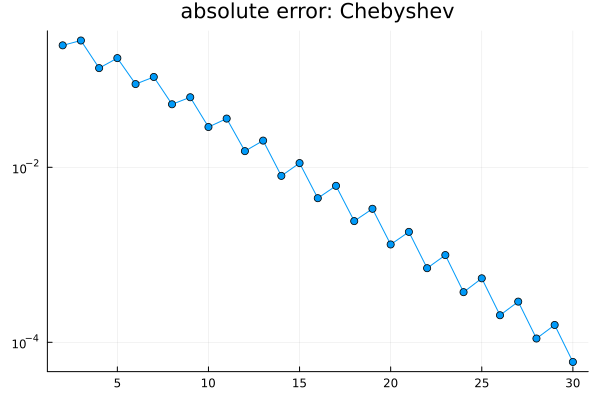

In [ ]:
 plt3 = plot( 2:N, err[2:N], marker=:circle, yaxis=:log, title="absolute error: Chebyshev", legend=false)

## What about approximation on $[-1, a] \cup [b, 1]$?

Leja points:

[ Info: Saved animation to C:\Users\jack6\julia_\images\Leja.gif


Plots.AnimatedGif("C:\\Users\\jack6\\julia_\\images\\Leja.gif")
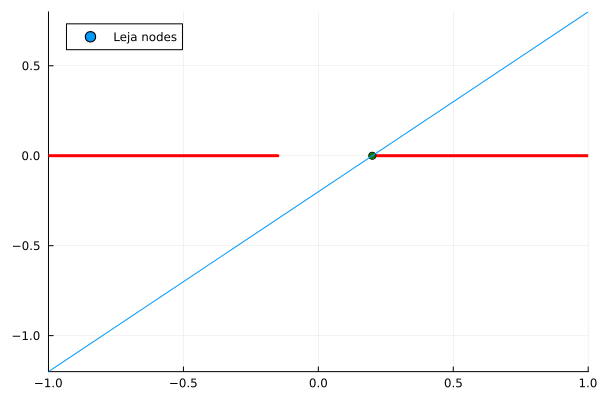

In [ ]:
# | include: false

N = 30;
a, b = -.15, .2;

m = [ -1:1e-3:a ; b:1e-3:1 ];
err = zeros(N)
x = [0.2]

anim = @animate for n ∈ 2:(2*N)

    if (n%2 == 0)

        plot( [-1,a], [0,0], lw=3, color="red", primary=false )
        plot!( [b,1], [0,0], lw=3, color="red", primary=false )
        scatter!( x[1:end-1], zeros(length(x)-1), label="Leja nodes" )
        scatter!( [x[end]], [0], label="Leja nodes",primary=false, color="green" )
        
        nodePoly = fromroots(Polynomial, x)

        plot!( nodePoly , xlims=[-1,1], ylims=[ minimum( nodePoly.(m) ), maximum( nodePoly.(m) )], primary=false)
        push!( x, m[argmax( abs.(nodePoly.(m)) )] )

    else 
        
        plot( [-1,a], [0,0], lw=3, color="red", primary=false )
        plot!( [b,1], [0,0], lw=3, color="red", primary=false )
        scatter!( x, zeros(length(x)), label="Leja nodes" )
        nodePoly = fromroots(Polynomial, x[1:end-1])
        plot!( nodePoly , xlims=[-1,1] , primary=false)
        plot!( [x[end], x[end]], [0., nodePoly(x[end])], 
            ylims=[ minimum( nodePoly.(m) ), maximum( nodePoly.(m) )],
            linestyle=:dash, primary=false, color="green")

    end
end

gif(anim, "images/Leja.gif", fps = 1)


[ Info: Saved animation to C:\Users\jack6\julia_\images\Leja.gif


Plots.AnimatedGif("C:\\Users\\jack6\\julia_\\images\\Leja.gif")
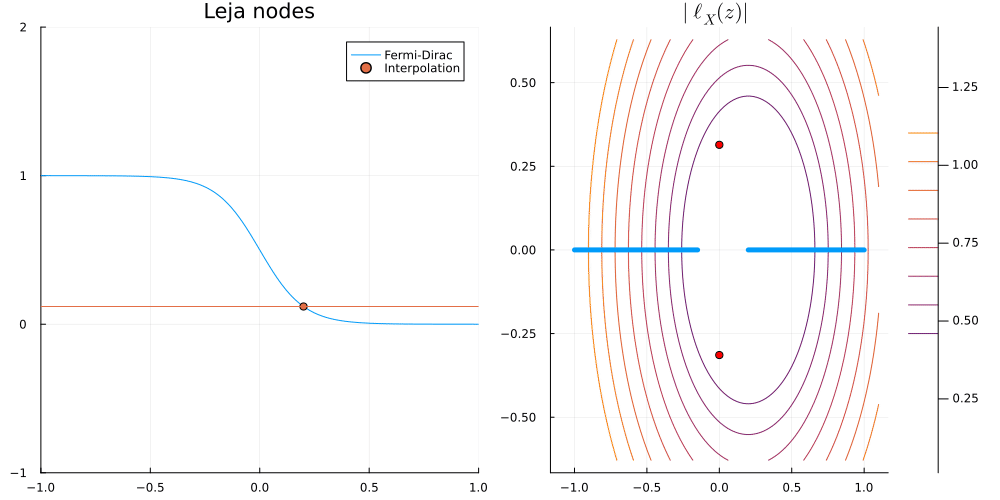

In [ ]:
# | include: false

N = 30;

m = [ -1:1e-3:a ; b:1e-3:1 ];
err = zeros(N);

anim = @animate for n ∈ 1:N

    p1 = fit( x[1:n], f.( x[1:n] ) )

    err[n] = maximum( abs.( p1.(m) - f.(m) ) )

    plt1 = plot( f, 
        label="Fermi-Dirac", title="Leja nodes",
        size=(500,500) )
    scatter!( plt1, x[1:n], f.( x[1:n] ),
        label="Interpolation" )
    plot!( plt1, p1, 
        xlims=[-1,1], ylims=[-1,2], 
        primary=false )
    
    nodePoly = fromroots(Polynomial, x[1:n])

    x1 = range(-1.1, 1.1, length=100)
    y1 = range(-2π/β, 2π/β, length=100)
    z1 = @. abs( nodePoly( x1' + 1im*y1 ) ) # imag( p1( x' + 1im*y ) )
    plt2 = contour( x1,y1,z1, 
                levels = ((1.25:.25:3)/exp(1)).^n)
                #color=["red", "blue", "red"],
                #clims=(-10,10) )
    scatter!(plt2, [μ -μ] , [-π/β π/β] , 
        color="red", primary=false, title=L"|\ell_X(z)|")
    plot!(plt2, [-1,a], [0,0], lw=5, primary=false)
    plot!(plt2, [b,1], [0,0], lw=5, primary=false)

    plot( plt1, plt2, size=(1000,500) )

   
end

gif(anim, "images/Leja.gif", fps = 1)


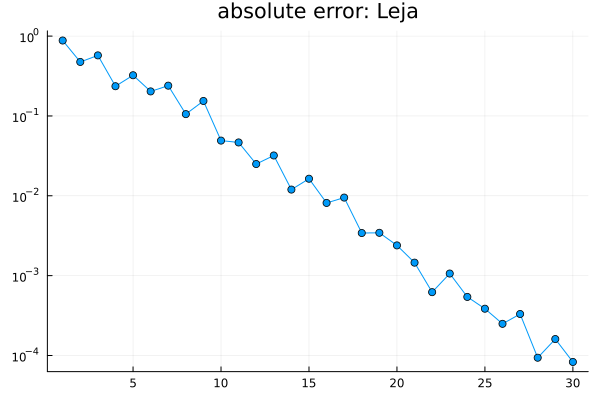

In [ ]:
plot( 1:N, err, marker=:circle, yaxis=:log, title="absolute error: Leja", legend=false)